# Quantization of the 1D-CNN + RR: FP32 vs INT8

The target device, the MAX78002, runs neural networks with 8-bit integer weights and activations. This notebook converts the trained 1D-CNN + RR (`1d_cnn_classifier_augmented.py`) from 32-bit floating point (FP32) to 8-bit integers (INT8) and measures the effect on classification performance and on model memory.

Two quantization methods are compared:
- **Post-training quantization (PTQ):** the trained FP32 weights are converted to INT8 directly. Activation ranges are calibrated on training data.
- **Quantization-aware training (QAT):** the network is fine-tuned while the INT8 rounding is simulated, then converted to INT8.

The architecture is not changed. Quantization uses the PT2E flow of [`torchao`](https://github.com/pytorch/ao), PyTorch's quantization library.

In [1]:
import copy
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

# Quiet import: torchao reports its optional GPU kernels as unavailable on a CPU-only install
logging.getLogger("torchao").setLevel(logging.ERROR)
logging.getLogger("torch.utils._pytree").setLevel(logging.ERROR)
import torchao
import torchao.quantization.pt2e as pt2e
import torchao.quantization.pt2e.quantizer.x86_inductor_quantizer as xiq
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
from torchao.quantization.pt2e.quantize_pt2e import convert_pt2e, prepare_pt2e, prepare_qat_pt2e

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
CLASSES = ["N", "S", "V", "F"]
LABELS = list(range(len(CLASSES)))
LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}

SRC_DIR = next(p / sub for p in [Path.cwd(), *Path.cwd().parents] for sub in ["", "src"]
               if (p / sub / "data_augmented" / "val.npz").exists())
DATA_DIR = SRC_DIR / "data_augmented"
CNN_DIR = SRC_DIR / "1D-CNN-augmented"
OUT_DIR = CNN_DIR / "quantization"
OUT_DIR.mkdir(exist_ok=True)
print("torch", torch.__version__, "| torchao", torchao.__version__)

torch 2.15.0+cpu | torchao 0.18.0


## 1. Data
The RR-augmented dataset from `prepare_data_augmented.py`: 200-sample beat windows plus 3 RR-interval features. Train is used for calibration and QAT, validation for monitoring, and test (DS2) for the final comparison.

In [2]:
def load_split(name):
    d = np.load(DATA_DIR / f"{name}.npz")
    x_sig = torch.tensor(d["X_signal"], dtype=torch.float32).unsqueeze(1)  # (n, 1, 200)
    x_rr = torch.tensor(d["X_rr"], dtype=torch.float32)                    # (n, 3)
    y = torch.tensor([LABEL_MAP[str(v)] for v in d["y"]])
    return x_sig, x_rr, y

data = {s: load_split(s) for s in ["train", "val", "test"]}
pd.DataFrame({s: np.bincount(d[2].numpy(), minlength=4) for s, d in data.items()}, index=CLASSES)

,train,val,test
N,38148,7691,44233
S,730,213,1836
V,2987,801,3220
F,384,30,388


## 2. FP32 model
The class below is a copy of `ECG_RR_MAX78002_Classifier` from the training script. Importing it from the script would retrain the model. The trained FP32 weights are loaded from `1d_cnn_classifier_augmented.pt`. The check below confirms that the copy reproduces the saved test predictions of the training script exactly.

In [3]:
class ECG_RR_MAX78002_Classifier(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.cnn_branch = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, stride=1, padding=3, bias=True), nn.ReLU(), nn.MaxPool1d(2, 2), nn.Dropout(0.1),
            nn.Conv1d(16, 32, kernel_size=5, stride=1, padding=2, bias=True), nn.ReLU(), nn.MaxPool1d(2, 2), nn.Dropout(0.1),
            nn.Conv1d(32, 64, kernel_size=3, stride=1, padding=1, bias=True), nn.ReLU(), nn.MaxPool1d(2, 2), nn.Dropout(0.1),
        )
        self.adaptive_pool = nn.AdaptiveAvgPool1d(4)
        self.cnn_fc = nn.Linear(64 * 4, 32, bias=True)
        self.rr_branch = nn.Sequential(nn.Linear(3, 16, bias=True), nn.ReLU(), nn.Dropout(0.1),
                                       nn.Linear(16, 16, bias=True), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(32 + 16, 32, bias=True), nn.ReLU(), nn.Dropout(0.1),
                                        nn.Linear(32, num_classes, bias=True))

    def forward(self, x_sig, x_rr):
        feat_sig = torch.flatten(self.adaptive_pool(self.cnn_branch(x_sig)), 1)
        feat_sig = F.relu(self.cnn_fc(feat_sig))
        feat_rr = self.rr_branch(x_rr)
        return self.classifier(torch.cat((feat_sig, feat_rr), dim=1))


@torch.no_grad()
def predict(model, split, batch_size=4096):
    x_sig, x_rr, _ = data[split]
    return torch.cat([model(x_sig[i:i + batch_size], x_rr[i:i + batch_size]).argmax(1)
                      for i in range(0, len(x_sig), batch_size)]).numpy()


fp32_model = ECG_RR_MAX78002_Classifier()
fp32_model.load_state_dict(torch.load(CNN_DIR / "1d_cnn_classifier_augmented.pt", weights_only=False)["state_dict"])
fp32_model.eval()
saved = np.load(CNN_DIR / "1d_cnn_predictions.npz")
assert np.array_equal(predict(fp32_model, "test"), saved["test_pred"]), "FP32 model does not reproduce the saved predictions"
print("FP32 model reproduces the saved test predictions of the training script.")

FP32 model reproduces the saved test predictions of the training script.


## 3. Quantization setup
**PT2E flow:**
1. **Export.** `torch.export` turns the model into a graph of operations, with a variable batch size.
2. **Annotate.** A *quantizer* marks which operations run in INT8. It also recognises patterns such as Conv1d → ReLU and Linear → ReLU and treats each as one fused operation, so the result is rounded to INT8 once instead of twice.
3. **Prepare.** Observers are inserted (PTQ), or fake-quantization modules (QAT), to learn the value range of every quantized tensor.
4. **Convert.** The weights are stored as INT8, and every activation passes through an INT8 quantize step.

The converted model is a reference INT8 model: its outputs equal those of INT8 arithmetic, while each operation is still computed by PyTorch on the CPU.

**Quantization scheme** (`X86InductorQuantizer`, default configuration):
- **Weights:** signed 8-bit, symmetric, one scale per output channel.
- **Activations:** unsigned 8-bit, one scale and zero point per tensor.

Both model inputs get their own scale, which matters here because their ranges differ widely: the signal is z-scored (about −5 to 6) and the RR features are in seconds (0 to 3.3).

In [4]:
quantizer = xiq.X86InductorQuantizer().set_global(xiq.get_default_x86_inductor_quantization_config())
qat_quantizer = xiq.X86InductorQuantizer().set_global(xiq.get_default_x86_inductor_quantization_config(is_qat=True))

example_inputs = (data["train"][0][:64].clone(), data["train"][1][:64].clone())  # clone: a slice would keep the whole training array
batch = torch.export.Dim("batch")
dynamic_batch = ({0: batch}, {0: batch})


def export(model):
    return torch.export.export(model, example_inputs, dynamic_shapes=dynamic_batch).module()


def input_scales(quantized_graph):
    # Scale (size of one INT8 step) of each model input in the converted graph.
    return {n.args[0].name: n.args[1] for n in quantized_graph.graph.nodes
            if n.target == torch.ops.quantized_decomposed.quantize_per_tensor.default
            and n.args[0].name in ("x_sig", "x_rr")}

## 4. Post-training quantization (PTQ)
The FP32 weights are quantized directly. To choose the INT8 scale of each activation, the prepared model observes the value ranges while the full training set is passed through it (calibration). Validation and test data are not used for calibration.

In [5]:
ptq_prepared = prepare_pt2e(export(copy.deepcopy(fp32_model).eval()), quantizer)
predict(ptq_prepared, "train")  # calibration pass
ptq_model = convert_pt2e(ptq_prepared)
print("input scales:", {k: round(v, 4) for k, v in input_scales(ptq_model).items()})

input scales: {'x_sig': 0.0377, 'x_rr': 0.0117}


## 5. Quantization-aware training (QAT)
**Why QAT:** the FP32 network was trained without any rounding. INT8 maps every weight and activation to one of 256 levels, which shifts the decision boundaries of a trained network slightly. The effect is largest in small networks such as this one (19,188 parameters) and at the fusion of inputs with very different ranges. QAT inserts *fake quantization* into the forward pass: values are rounded to their INT8 levels but kept in floating point, so the gradients can still flow (straight-through estimator). During fine-tuning the weights adapt to the rounding.

**How it was performed:**
- **Starting point:** the trained FP32 weights.
- **Training setup:** the same as the original training, i.e. square-root weighted sampling, square-root class-weighted cross-entropy, Gaussian input noise (σ = 0.01), Adam with weight decay 1e-4, batch size 64 and seed 42.
- **Learning rate:** 1e-4, ten times lower than the original training, because the network is only fine-tuned.
- **Epochs:** 5. The INT8 ranges (observers) are frozen after epoch 3, so the last two epochs train against fixed ranges.
- **Model kept:** the model after the last epoch, as in the original training, without validation-based selection.
- **Dropout:** the model is exported in training mode, so dropout keeps its rate of 0.1. torchao's helper for switching an exported model to training mode would replace it with a fixed rate of 0.5. Validation is therefore computed on an evaluation-mode copy after each epoch.

In [6]:
QAT_EPOCHS, QAT_LR, FREEZE_OBSERVERS_AFTER = 5, 1e-4, 3

torch.manual_seed(SEED)
np.random.seed(SEED)
x_sig_tr, x_rr_tr, y_tr = data["train"]
class_w = 1.0 / np.sqrt(np.bincount(y_tr.numpy()))
sampler = WeightedRandomSampler(torch.tensor(class_w[y_tr.numpy()], dtype=torch.float),
                                num_samples=len(y_tr), replacement=True)
loader = DataLoader(TensorDataset(x_sig_tr, x_rr_tr, y_tr), batch_size=64, sampler=sampler)

qat_prepared = prepare_qat_pt2e(export(copy.deepcopy(fp32_model).train()), qat_quantizer)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_w, dtype=torch.float32))
optimizer = torch.optim.Adam(qat_prepared.parameters(), lr=QAT_LR, weight_decay=1e-4)


def eval_copy(prepared):
    model = copy.deepcopy(prepared)
    pt2e.move_exported_model_to_eval(model)
    return model


y_val = data["val"][2].numpy()
macro_f1 = lambda y_true, y_pred: f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
qat_history = []
for epoch in range(1, QAT_EPOCHS + 1):
    if epoch > FREEZE_OBSERVERS_AFTER:
        qat_prepared.apply(pt2e.disable_observer)
    total = 0.0
    for x_sig, x_rr, yb in loader:
        x_sig = x_sig + torch.randn_like(x_sig) * 0.01
        optimizer.zero_grad()
        loss = criterion(qat_prepared(x_sig, x_rr), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
    qat_history.append({"epoch": epoch, "train_loss": total / len(y_tr),
                        "val_macro_f1 (fake-quant)": macro_f1(y_val, predict(eval_copy(qat_prepared), "val"))})

qat_model = convert_pt2e(eval_copy(qat_prepared))
print("input scales:", {k: round(v, 4) for k, v in input_scales(qat_model).items()})
pd.DataFrame(qat_history).set_index("epoch").round(4)

input scales: {'x_sig': 0.0367, 'x_rr': 0.0063}


,train_loss,val_macro_f1 (fake-quant)
epoch,,
1,0.0497,0.4890
2,0.0465,0.4939
3,0.0438,0.5174
4,0.0405,0.5159
5,0.0447,0.4775


## 6. FP32 vs INT8
For each model:
- **Performance:** validation and test results.
- **Agreement:** the share of test beats that receive the same prediction as the FP32 model.
- **Parameter memory:** the storage the model needs for its parameters. FP32 stores 4 bytes per weight and bias. INT8 stores 1 byte per weight, plus the biases in 32 bits and one 32-bit scale per output channel.

In [7]:
def fp32_param_bytes(model):
    return sum(p.numel() * p.element_size() for p in model.parameters())


def int8_param_bytes(quantized_graph, fp32):
    # INT8 weights + FP32 biases + one FP32 scale per output channel. Symmetric weights have zero points
    # of 0, which are not stored. The FP32 weight copies left in the exported graph are unused.
    sd = quantized_graph.state_dict()
    int8_weights = sum(t.numel() for t in sd.values() if t.dtype == torch.int8)
    scales = sum(t.numel() * 4 for k, t in sd.items() if k.startswith("_scale_"))
    biases = sum(p.numel() * 4 for n, p in fp32.named_parameters() if n.endswith("bias"))
    return int8_weights + scales + biases


models = {"FP32": fp32_model, "INT8 (PTQ)": ptq_model, "INT8 (QAT)": qat_model}
preds = {name: {s: predict(m, s) for s in ["val", "test"]} for name, m in models.items()}
y_true = {s: data[s][2].numpy() for s in ["val", "test"]}
memory = {"FP32": fp32_param_bytes(fp32_model),
          "INT8 (PTQ)": int8_param_bytes(ptq_model, fp32_model),
          "INT8 (QAT)": int8_param_bytes(qat_model, fp32_model)}

rows = []
for name in models:
    f1_test = f1_score(y_true["test"], preds[name]["test"], labels=LABELS, average=None, zero_division=0)
    rows.append({
        "model": name,
        "val macro-F1": macro_f1(y_true["val"], preds[name]["val"]),
        "test accuracy": accuracy_score(y_true["test"], preds[name]["test"]),
        "test macro-F1": macro_f1(y_true["test"], preds[name]["test"]),
        **{f"test F1 {c}": v for c, v in zip(CLASSES, f1_test)},
        "agreement with FP32 (test)": (preds[name]["test"] == preds["FP32"]["test"]).mean(),
        "parameter memory (KB)": memory[name] / 1024,
    })
comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4)

,val macro-F1,test accuracy,test macro-F1,test F1 N,test F1 S,test F1 V,test F1 F,agreement with FP32 (test),parameter memory (KB)
model,,,,,,,,,
FP32,0.5024,0.8151,0.4980,0.8929,0.1921,0.8910,0.0160,1.0000,74.9531
INT8 (PTQ),0.5011,0.8157,0.4976,0.8933,0.1893,0.8923,0.0154,0.9926,20.1875
INT8 (QAT),0.4777,0.8537,0.4983,0.9182,0.1745,0.8924,0.0081,0.9477,20.1875


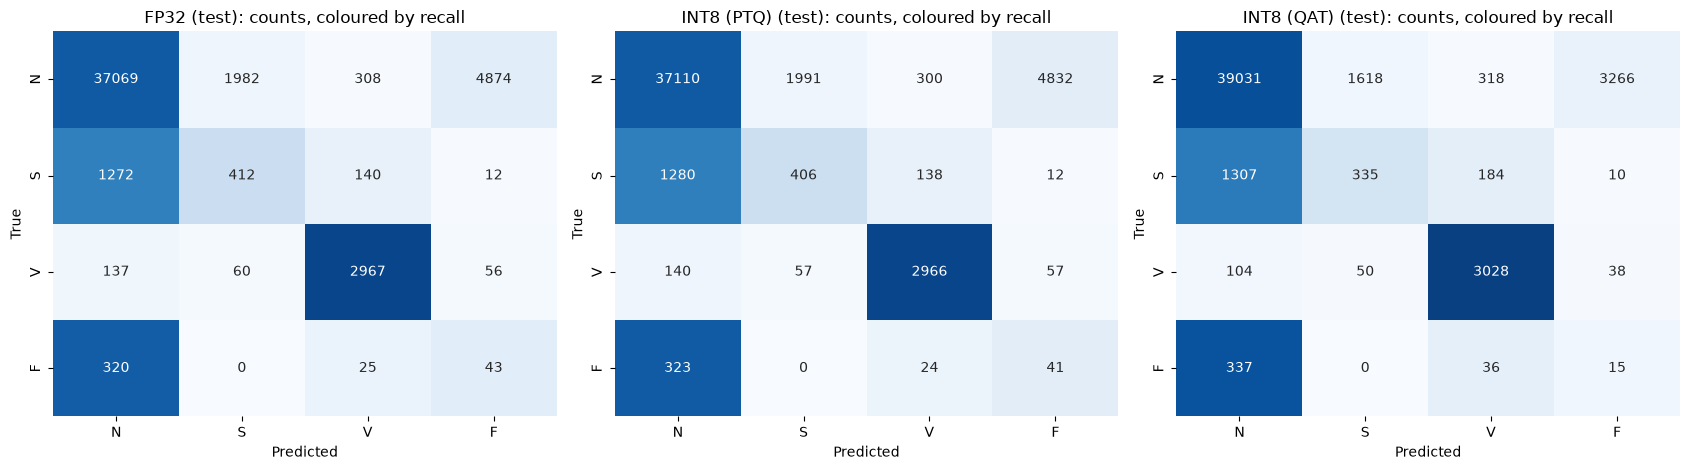

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_true["test"], preds[name]["test"], labels=LABELS)
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt="d", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"{name} (test): counts, coloured by recall")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

In [9]:
# Save the INT8 models as exported programs (reload with torch.export.load(path).module()) and the results
for name, model in [("ptq", ptq_model), ("qat", qat_model)]:
    program = torch.export.export(model, example_inputs, dynamic_shapes=dynamic_batch)
    torch.export.save(program, OUT_DIR / f"cnn_int8_{name}.pt2")
    reloaded = torch.export.load(OUT_DIR / f"cnn_int8_{name}.pt2").module()
    assert np.array_equal(predict(reloaded, "test"), preds[f"INT8 ({name.upper()})"]["test"])

np.savez(OUT_DIR / "quantization_predictions.npz",
         fp32_val_pred=preds["FP32"]["val"], fp32_test_pred=preds["FP32"]["test"],
         ptq_val_pred=preds["INT8 (PTQ)"]["val"], ptq_test_pred=preds["INT8 (PTQ)"]["test"],
         qat_val_pred=preds["INT8 (QAT)"]["val"], qat_test_pred=preds["INT8 (QAT)"]["test"],
         val_true=y_true["val"], test_true=y_true["test"], classes=np.array(CLASSES))
comparison.to_csv(OUT_DIR / "fp32_vs_int8.csv")
pd.DataFrame(qat_history).to_csv(OUT_DIR / "qat_history.csv", index=False)
print(sorted(p.name for p in OUT_DIR.iterdir()))

['cnn_int8_ptq.pt2', 'cnn_int8_qat.pt2', 'fp32_vs_int8.csv', 'qat_history.csv', 'quantization_predictions.npz']


## 7. Conclusions

| Model | Val macro-F1 | Test accuracy | Test macro-F1 | Test F1 S | Agreement with FP32 | Parameter memory |
|---|---|---|---|---|---|---|
| FP32 | 0.502 | 0.815 | 0.498 | 0.192 | 100% | 75.0 KB |
| INT8, PTQ | 0.501 | 0.816 | 0.498 | 0.189 | 99.3% | 20.2 KB |
| INT8, QAT | 0.478 | 0.854 | 0.498 | 0.175 | 94.8% | 20.2 KB |

- **Quantization to INT8 does not change model performance.** With PTQ, test macro-F1 is unchanged (0.4976 vs 0.4980), every per-class F1 stays within 0.003 of FP32, and 99.3% of the test beats keep exactly the FP32 prediction. The signal input is represented in INT8 steps of 0.038 and the RR input in steps of 0.012 s (12 ms), fine enough to preserve the timing information that S detection depends on.
- **Parameter memory shrinks 3.7×** (75.0 → 20.2 KB). This is not the full 4× because the biases stay in 32 bits and every output channel stores its own scale.
- **QAT was not needed.** PTQ already preserves the FP32 performance, so QAT has no quantization error to recover. QAT reaches the same test macro-F1 (0.498), but with a different balance between the classes: higher accuracy and N F1, lower S and F F1, and only 94.8% agreement with FP32. That shift comes from the 5 extra training epochs, not from quantization. Its validation macro-F1 varies between 0.478 and 0.517 from epoch to epoch, so continued training moves the model around rather than improving it.
- **PTQ is the preferred INT8 model:** it reproduces the FP32 model in a quarter of the memory without retraining.
- **Limitation:** the INT8 models use torchao's x86 quantization scheme (per-channel weight scales, asymmetric activations). The MAX78002 toolchain uses its own 8-bit scheme and applies QAT during training, so the on-device numbers may differ slightly. That is verified separately in the deployment section.
